Analyse de Sentiment – Fusion et Analyse du Dataset Final

Ce notebook présente :

- La fusion de deux datasets issus de G1 et G2
- Le nettoyage et la normalisation des données
- La suppression des doublons
- L’analyse exploratoire du dataset final

Objectif : obtenir un dataset propre et fiable pour l’analyse de sentiment.


Chargement des données

Nous chargeons deux datasets :
- Dataset 1 groupe :  hiba el hamdani et nawal ait-tami
- Dataset 2 groupe :  ihsane foudal et kadidiatou dem


In [36]:
import json
import pandas as pd
file1 = r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\final_filtered.json"
file2 = r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\THE_ULTIMATE_DARIJA_DATASET_40000_FINAL_CLEAN.json"

with open(file1, "r", encoding="utf-8") as f:
    data1 = json.load(f)

with open(file2, "r", encoding="utf-8") as f:
    data2 = json.load(f)

print("Dataset 1 :", len(data1))
print("Dataset 2 :", len(data2))

Dataset 1 : 43554
Dataset 2 : 39999


Vérification du format des données


In [37]:
print(" Exemples dataset 1 :")
for i in range(3):
    print(data1[i])
    print("---")

print("\n Exemples dataset 2 :")
for i in range(3):
    print(data2[i])
    print("---")

 Exemples dataset 1 :
{'comment_id': 'UgwodTeGOvTeIGNux8Z4AaABAg', 'text_clean': 'مقرلتيناش كيفاش مديرو مليون دولار', 'sentiment': 'Neutre'}
---
{'comment_id': 'Ugw9ANN-50l1Di_FLQp4AaABAg', 'text_clean': 'lah y barek concept nadi kat wa33i shabab', 'sentiment': 'Positif'}
---
{'comment_id': 'UgynNafjO6kDQRemBZ14AaABAg', 'text_clean': 'الموضوع كيف تتحرر من وسايل التواصل الاجتماعي', 'sentiment': 'Neutre'}
---

 Exemples dataset 2 :
{'comment_id': 'UgyFgiPGSZ8XDKx2vHp4AaABAg', 'text_clean': 'اختي صفاء اول نعلق حياتي لشي فيديو ولكن الفيديو نهار كنتصنت كنكوني مشوقة امتى نرجع نكمل ليلة كاملة كدربني لفيقة كنلقى راسي كنفكر فهاد القصة', 'sentiment': 'positif'}
---
{'comment_id': 'UgzQD8HV0HxpZSW8LI14AaABAg', 'text_clean': 'akbar 7a9od lrgragi nsito achno dwzti alih nti9o', 'sentiment': 'negatif'}
---
{'comment_id': 'UgyVgRARZJda10LYmH54AaABAg', 'text_clean': 'قال ليك الوداد بينات الاهلي صعيبة القاب خدينا عليهم تقولش هاديك العرجة كايتلاقاو كايقصيوهم هههه تفو', 'sentiment': 'negatif'}
---


On remarque que :

- Certains sentiments sont écrits comme : "Positive", "NEGATIVE", " neutre "
- Cela peut poser problème lors de l'analyse 


Normalisation des labels de sentiment

In [38]:
# Fonction de nettoyage
def normalize_sentiment(data):
    for item in data:
        if "sentiment" in item and item["sentiment"]:
            item["sentiment"] = item["sentiment"].lower().strip()

# Appliquer sur les deux datasets
normalize_sentiment(data1)
normalize_sentiment(data2)

Vérification avec affichage d'exemples

In [39]:
print("🔹 Dataset 1 après normalisation :")
for item in data1[:3]:
    print(item)
    print("---")

print("\n🔹 Dataset 2 après normalisation :")
for item in data2[:3]:
    print(item)
    print("---")

🔹 Dataset 1 après normalisation :
{'comment_id': 'UgwodTeGOvTeIGNux8Z4AaABAg', 'text_clean': 'مقرلتيناش كيفاش مديرو مليون دولار', 'sentiment': 'neutre'}
---
{'comment_id': 'Ugw9ANN-50l1Di_FLQp4AaABAg', 'text_clean': 'lah y barek concept nadi kat wa33i shabab', 'sentiment': 'positif'}
---
{'comment_id': 'UgynNafjO6kDQRemBZ14AaABAg', 'text_clean': 'الموضوع كيف تتحرر من وسايل التواصل الاجتماعي', 'sentiment': 'neutre'}
---

🔹 Dataset 2 après normalisation :
{'comment_id': 'UgyFgiPGSZ8XDKx2vHp4AaABAg', 'text_clean': 'اختي صفاء اول نعلق حياتي لشي فيديو ولكن الفيديو نهار كنتصنت كنكوني مشوقة امتى نرجع نكمل ليلة كاملة كدربني لفيقة كنلقى راسي كنفكر فهاد القصة', 'sentiment': 'positif'}
---
{'comment_id': 'UgzQD8HV0HxpZSW8LI14AaABAg', 'text_clean': 'akbar 7a9od lrgragi nsito achno dwzti alih nti9o', 'sentiment': 'negatif'}
---
{'comment_id': 'UgyVgRARZJda10LYmH54AaABAg', 'text_clean': 'قال ليك الوداد بينات الاهلي صعيبة القاب خدينا عليهم تقولش هاديك العرجة كايتلاقاو كايقصيوهم هههه تفو', 'sentiment'

Fusion des datasets

Objectif :
- Combiner toutes les données
- Supprimer les doublons
- Garder une seule version de chaque commentaire

 On utilise `comment_id` comme identifiant unique.

In [40]:
# Combiner les deux datasets
combined = data1 + data2

print(" Nombre total avant suppression des doublons :", len(combined))

 Nombre total avant suppression des doublons : 83553


Suppression des doublons

In [41]:
unique_data = {}

# Ajouter dataset 1
for item in data1:
    cid = item.get("comment_id")
    if cid and item.get("sentiment") is not None:
        unique_data[cid] = item

# Ajouter dataset 2 (priorité → écrase les doublons)
for item in data2:
    cid = item.get("comment_id")
    if cid and item.get("sentiment") is not None:
        unique_data[cid] = item

# Dataset final
final_data = list(unique_data.values())

print("📊 Nombre après suppression des doublons :", len(final_data))

📊 Nombre après suppression des doublons : 83411


Sauvegarde du dataset final

In [42]:
output_path = r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\totaldata.json"

import json
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(final_data, f, ensure_ascii=False, indent=4)

print(" Dataset final sauvegardé dans :", output_path)

 Dataset final sauvegardé dans : C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\totaldata.json


STRUCTURE EDA

In [43]:
import json
import pandas as pd

file_path = r"C:\Users\elham\Desktop\youtube-sentiment-analysis\data\labeled\totaldata.json"

with open(file_path, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)

print(df.shape)
df.head()

(83411, 3)


,comment_id,text_clean,sentiment
0,UgwodTeGOvTeIGNux8Z4AaABAg,مقرلتيناش كيفاش مديرو مليون دولار,neutre
1,Ugw9ANN-50l1Di_FLQp4AaABAg,lah y barek concept nadi kat wa33i shabab,positif
2,UgynNafjO6kDQRemBZ14AaABAg,الموضوع كيف تتحرر من وسايل التواصل الاجتماعي,neutre
3,UgzmAQ1zH4yG2_-enKJ4AaABAg,فاش شفت السطوري و الترويج قلت غا تكون شي حاجه ...,positif
4,UgzwHC0zOu9rFQPvtBt4AaABAg,رياله وصلات خويا سيمو,neutre


Aperçu global des données

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83411 entries, 0 to 83410
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   comment_id  83411 non-null  object
 1   text_clean  83411 non-null  object
 2   sentiment   83411 non-null  object
dtypes: object(3)
memory usage: 1.9+ MB


In [46]:
df.describe(include="all")

,comment_id,text_clean,sentiment
count,83411,83411,83411
unique,83411,83382,3
top,UgwodTeGOvTeIGNux8Z4AaABAg,اشهار,positif
freq,1,2,28622


Vérification des valeurs manquantes

In [45]:
df.isnull().sum()

comment_id    0
text_clean    0
sentiment     0
dtype: int64

Distribution des classes

sentiment
positif    28622
negatif    27827
neutre     26962
Name: count, dtype: int64


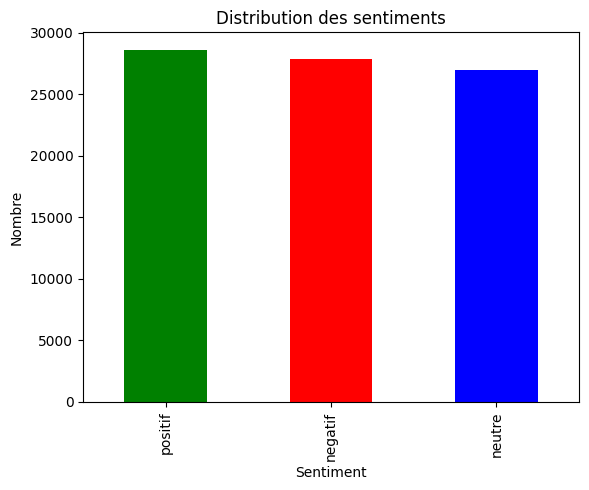

In [49]:
import matplotlib.pyplot as plt
class_counts = df["sentiment"].value_counts()
print(class_counts)

class_counts.plot(
    kind="bar",
    title="Distribution des sentiments",
    color=["green", "red", "blue"]  # adapte selon tes classes
)

plt.xlabel("Sentiment")
plt.ylabel("Nombre")
plt.show()

Après analyse du dataset final, on obtient la répartition suivante :

- Positif : 28622
- Négatif : 27827
- Neutre : 26962

On remarque que :

- Les trois classes sont relativement équilibrées
- La classe "positif" est légèrement dominante
- La classe "neutre" est légèrement moins représentée

Analyse du langage

 Répartition des langues :
language
darija en arabe          52555
latin / arabizi          27708
mix (arabizi + arabe)     3148
Name: count, dtype: int64


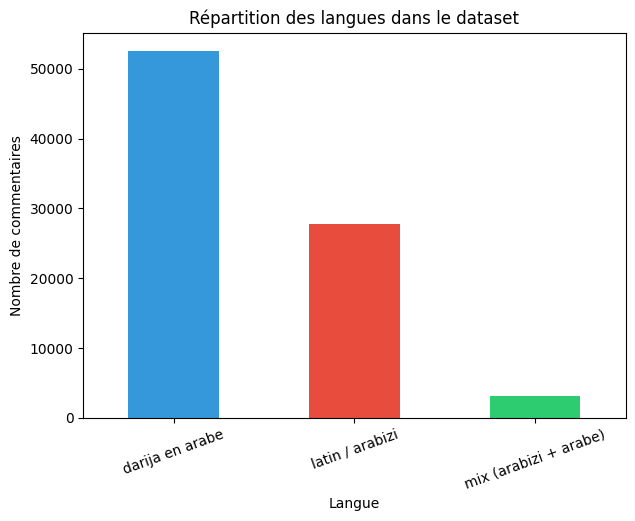

 Exemples par langue (aléatoires) :

LANGUE : darija en arabe
Exemple 1 : الله ينزل عليكم اللعنه خصكم نتوما 1 سنين ديال الحبس
Exemple 2 : صفوءة الغزالة توحشناك


LANGUE : latin / arabizi
Exemple 1 : halqa hareb liha nadyiin
Exemple 2 : wssalna mea halilozi


LANGUE : mix (arabizi + arabe)
Exemple 1 : let s go go كا تهرضي معgeorge كنت نقرا homeschool by the wy عيقتي تكلمي you can do it تكلمي عادي بلاالهدرةالخاوية
Exemple 2 : حاليا الاسبانيون كيسميو المغربي بمورو moro امرو وان دبا خاصنا نبقاو كل مرا نقولو ليهم عيطو علينا بالمغربي




In [58]:
import matplotlib.pyplot as plt
import re

# Détection de langue
def detect_language(text):
    text = str(text)

    has_arabic = bool(re.search(r'[\u0600-\u06FF]', text))
    has_latin = bool(re.search(r'[a-zA-Z]', text))

    if has_arabic and has_latin:
        return "mix (arabizi + arabe)"
    elif has_arabic:
        return "darija en arabe"
    elif has_latin:
        return "latin / arabizi"
    else:
        return "autre"

# Appliquer la détection
df["language"] = df["text_clean"].apply(detect_language)

#  Comptage
lang_counts = df["language"].value_counts()

print(" Répartition des langues :")
print(lang_counts)

#  Graphe
plt.figure(figsize=(7,5))
lang_counts.plot(kind="bar", color=["#3498db", "#e74c3c", "#2ecc71", "#f1c40f"])
plt.title("Répartition des langues dans le dataset")
plt.xlabel("Langue")
plt.ylabel("Nombre de commentaires")
plt.xticks(rotation=20)
plt.show()

print(" Exemples par langue (aléatoires) :\n")

for lang in df["language"].unique():
    
    print("=" * 50)
    print(f"LANGUE : {lang}")
    print("=" * 50)
    
    # prendre des exemples aléatoires
    samples = df[df["language"] == lang]["text_clean"].dropna().sample(2, random_state=42)
    
    for i, ex in enumerate(samples, 1):
        print(f"Exemple {i} : {ex}")
    
    print("\n")

Analyse de la longueur des commentaires

         STATISTIQUES - LONGUEUR DES COMMENTAIRES
   Nombre total de commentaires : 83,411
   Longueur moyenne             : 58.8 caractères
   Médiane                      : 37.0 caractères
   Mode (valeur la + fréquente) : 18 caractères
   Minimum                      : 1 caractères
   Maximum                      : 4278 caractères
   Écart-type                   : 81.9


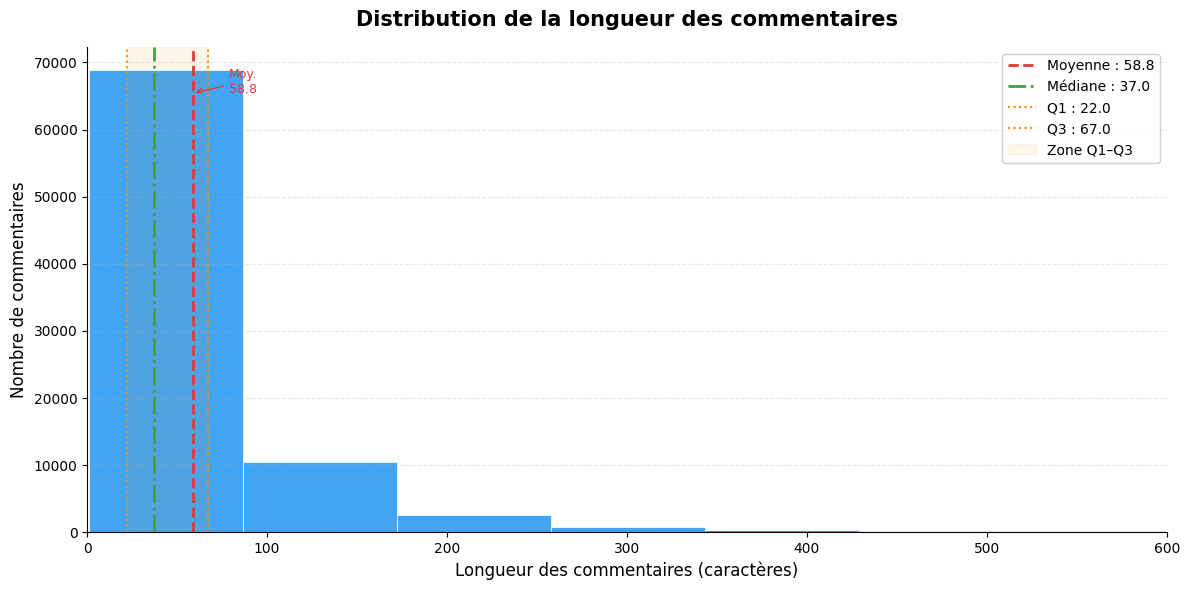

In [70]:
import matplotlib.pyplot as plt
import numpy as np

# Calcul de la longueur
df["length"] = df["text_clean"].apply(lambda x: len(str(x)))

# ── Statistiques ──────────────────────────────────────────
stats = df["length"].describe()
moyenne   = df["length"].mean()
mediane   = df["length"].median()
mode_val  = df["length"].mode()[0]
q1        = df["length"].quantile(0.25)
q3        = df["length"].quantile(0.75)

print("=" * 55)
print("         STATISTIQUES - LONGUEUR DES COMMENTAIRES")
print("=" * 55)
print(f"   Nombre total de commentaires : {int(stats['count']):,}")
print(f"   Longueur moyenne             : {moyenne:.1f} caractères")
print(f"   Médiane                      : {mediane:.1f} caractères")
print(f"   Mode (valeur la + fréquente) : {mode_val} caractères")
print(f"   Minimum                      : {int(stats['min'])} caractères")
print(f"   Maximum                      : {int(stats['max'])} caractères")
print(f"   Écart-type                   : {stats['std']:.1f}")
print("=" * 55)

# ── Graphique ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

n, bins, patches = ax.hist(
    df["length"], bins=50,
    color="#2196F3", edgecolor="white",
    linewidth=0.6, alpha=0.85
)

# Lignes verticales des statistiques
ax.axvline(moyenne, color="#E53935", linewidth=2,
           linestyle="--", label=f"Moyenne : {moyenne:.1f}")
ax.axvline(mediane, color="#43A047", linewidth=2,
           linestyle="-.",  label=f"Médiane : {mediane:.1f}")
ax.axvline(q1, color="#FB8C00", linewidth=1.5,
           linestyle=":",  label=f"Q1 : {q1:.1f}")
ax.axvline(q3, color="#FB8C00", linewidth=1.5,
           linestyle=":",  label=f"Q3 : {q3:.1f}")

# Zone interquartile (Q1–Q3)
ax.axvspan(q1, q3, alpha=0.08, color="#FB8C00", label="Zone Q1–Q3")

# Annotation de la moyenne sur le graphe
ax.annotate(
    f"Moy.\n{moyenne:.1f}",
    xy=(moyenne, n.max() * 0.95),
    xytext=(moyenne + 20, n.max() * 0.95),
    fontsize=9, color="#E53935",
    arrowprops=dict(arrowstyle="->", color="#E53935")
)

# Mise en forme
ax.set_xlim(0, 600)
ax.set_title("Distribution de la longueur des commentaires",
             fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Longueur des commentaires (caractères)", fontsize=12)
ax.set_ylabel("Nombre de commentaires", fontsize=12)
ax.legend(fontsize=10, framealpha=0.9)
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Calcul des métriques (taux d’erreur, corrections)

Police arabe : arial.ttf

════════════════════════════════════════════════════════════
           RÉSUMÉ FINAL — LLM vs HUMAIN
════════════════════════════════════════════════════════════
  Comparés              : 83,397
  Correct               : 79,075 (94.82%)
  Erreurs               : 4,322 (5.18%)
  Classe difficile      : negatif (8.0%)
  Meilleure classe      : neutre (2.1%)
════════════════════════════════════════════════════════════


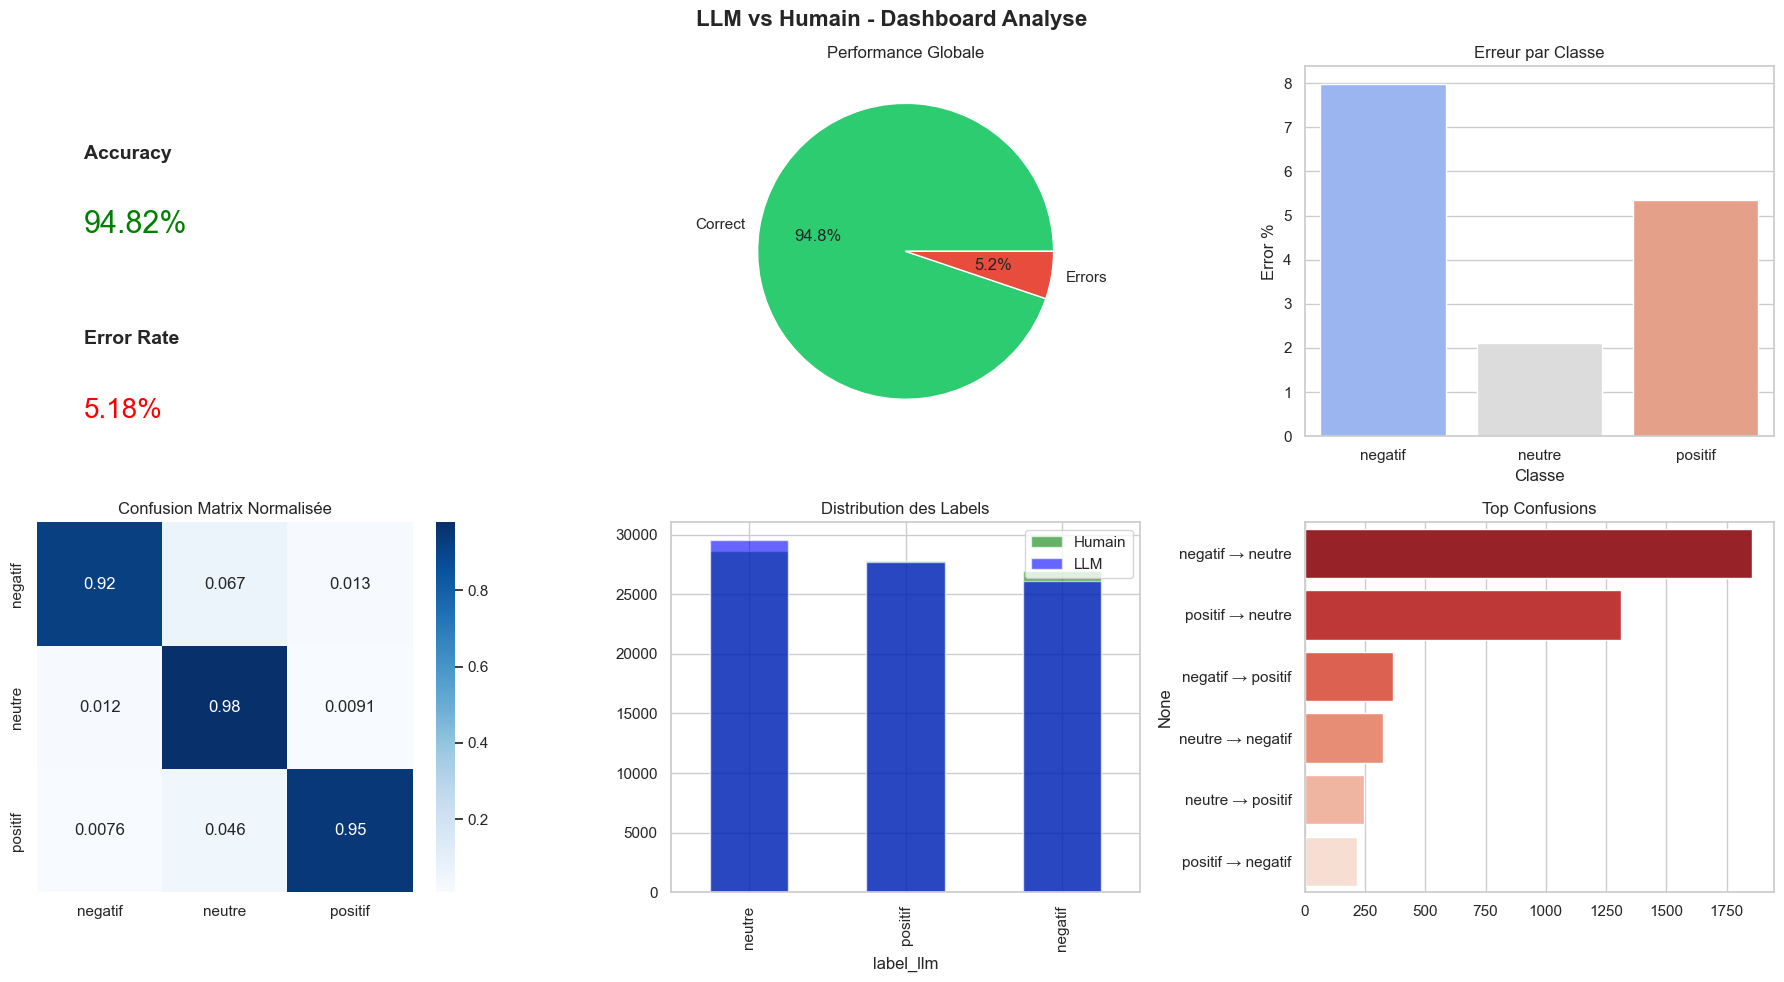


══════════════════════════════════════════════════════════════════════
        EXEMPLES DE CORRECTIONS HUMAINES PAR TYPE
══════════════════════════════════════════════════════════════════════

──────────────────────────────────────────────────────────────────────
  TYPE : Neutre → Negatif  (1854 cas — 42.9% des erreurs)
──────────────────────────────────────────────────────────────────────

  Exemple 1 :
    Commentaire : naari fin redna
    LLM disait  : NEUTRE
    Humain a mis: NEGATIF  ← correction

  Exemple 2 :
    Commentaire : ومشي غبرات وغملات
    LLM disait  : NEUTRE
    Humain a mis: NEGATIF  ← correction

  Exemple 3 :
    Commentaire : سيمولايف ليكايمعني عليا امعني علي مو
    LLM disait  : NEUTRE
    Humain a mis: NEGATIF  ← correction

──────────────────────────────────────────────────────────────────────
  TYPE : Neutre → Positif  (1314 cas — 30.4% des erreurs)
──────────────────────────────────────────────────────────────────────

  Exemple 1 :
    Commentaire : شي ڤديو

C:\Users\elham\AppData\Local\Temp\ipykernel_10648\2461436246.py:238: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.savefig("tableau_corrections.png", dpi=180, bbox_inches="tight", facecolor="white")
C:\Users\elham\AppData\Local\Temp\ipykernel_10648\2461436246.py:238: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.savefig("tableau_corrections.png", dpi=180, bbox_inches="tight", facecolor="white")
c:\Users\elham\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\elham\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


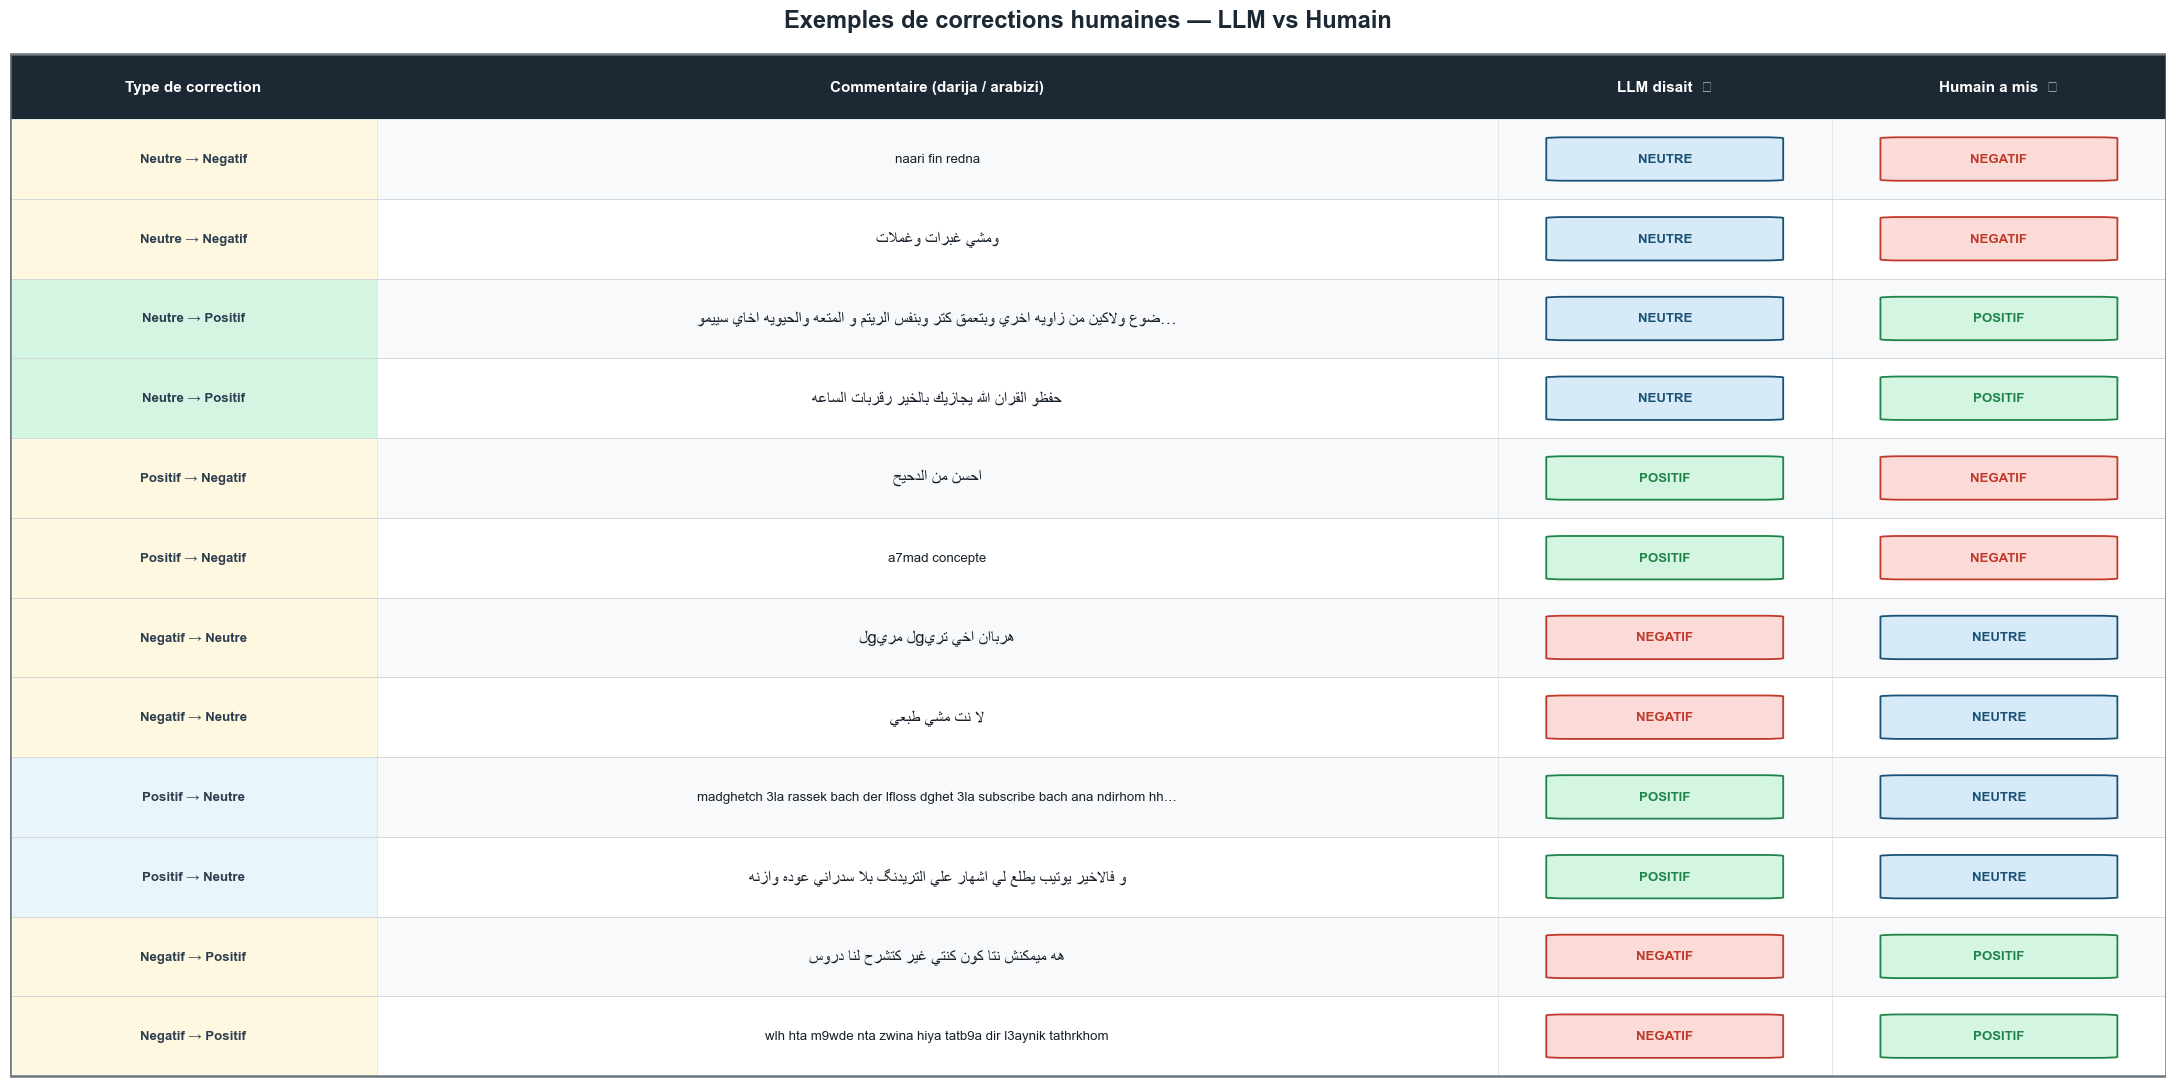

Tableau sauvegardé : tableau_corrections.png


In [19]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.font_manager as fm
import seaborn as sns
import arabic_reshaper
from bidi.algorithm import get_display
from sklearn.metrics import confusion_matrix
import pandas as pd
import os

# ── Détection automatique de la police arabe (Windows / Linux / Mac) ──
def get_arabic_font(size=12):
    """
    Cherche automatiquement une police supportant l'arabe selon l'OS.
    Windows  → Arial, Tahoma, Segoe UI (déjà installées)
    Linux    → Amiri (si installée via apt)
    Mac      → Arial, Geeza Pro
    """
    candidates = [
        # Linux/Mac — Amiri (meilleure qualité)
        '/usr/share/fonts/opentype/fonts-hosny-amiri/Amiri-Regular.ttf',
        '/usr/share/fonts/truetype/fonts-hosny-amiri/Amiri-Regular.ttf',
        # Windows — polices système natives
        r'C:\Windows\Fonts\arial.ttf',
        r'C:\Windows\Fonts\tahoma.ttf',
        r'C:\Windows\Fonts\segoeui.ttf',
        r'C:\Windows\Fonts\calibri.ttf',
        # Mac
        '/Library/Fonts/Arial.ttf',
        '/System/Library/Fonts/Supplemental/Arial.ttf',
    ]
    for path in candidates:
        if os.path.exists(path):
            fm.fontManager.addfont(path)
            print(f"Police arabe : {os.path.basename(path)}")
            return fm.FontProperties(fname=path, size=size)
    print("Aucune police arabe trouvée — texte arabe peut être mal affiché")
    return fm.FontProperties(size=size)

ARABIC_FONT = get_arabic_font(12)

def ar(text):
    """Reshape + bidi — connecte les lettres arabes et inverse le sens."""
    try:
        return get_display(arabic_reshaper.reshape(str(text)))
    except Exception:
        return str(text)

sns.set_theme(style="whitegrid")

# ═══════════════════════════════════════
# 1. STATS TEXTE
# ═══════════════════════════════════════
print("\n" + "═"*60)
print("           RÉSUMÉ FINAL — LLM vs HUMAIN")
print("═"*60)
print(f"  Comparés              : {total:,}")
print(f"  Correct               : {correct:,} ({accuracy:.2f}%)")
print(f"  Erreurs               : {errors:,} ({error_rate:.2f}%)")
print(f"  Classe difficile      : {worst['Classe']} ({worst['Error_rate']:.1f}%)")
print(f"  Meilleure classe      : {best['Classe']} ({best['Error_rate']:.1f}%)")
print("═"*60)

# ═══════════════════════════════════════
# 2. DASHBOARD
# ═══════════════════════════════════════
fig = plt.figure(figsize=(18, 10))
fig.suptitle("LLM vs Humain - Dashboard Analyse", fontsize=16, fontweight="bold")

ax1 = plt.subplot(2, 3, 1)
ax1.axis("off")
ax1.text(0.1, 0.75, "Accuracy",         fontsize=14, fontweight="bold")
ax1.text(0.1, 0.55, f"{accuracy:.2f}%", fontsize=22, color="green")
ax1.text(0.1, 0.25, "Error Rate",       fontsize=14, fontweight="bold")
ax1.text(0.1, 0.05, f"{error_rate:.2f}%", fontsize=20, color="red")

ax2 = plt.subplot(2, 3, 2)
ax2.pie([correct, errors], labels=["Correct", "Errors"],
        autopct="%1.1f%%", colors=["#2ECC71", "#E74C3C"])
ax2.set_title("Performance Globale")

ax3 = plt.subplot(2, 3, 3)
sns.barplot(data=df_class, x="Classe", y="Error_rate",
            hue="Classe", palette="coolwarm", legend=False, ax=ax3)
ax3.set_title("Erreur par Classe")
ax3.set_ylabel("Error %")

ax4 = plt.subplot(2, 3, 4)
cm = confusion_matrix(y_true, y_pred, normalize="true")
sns.heatmap(cm, annot=True, cmap="Blues",
            xticklabels=sorted(df["label_llm"].unique()),
            yticklabels=sorted(df["label_humain"].unique()), ax=ax4)
ax4.set_title("Confusion Matrix Normalisée")

ax5 = plt.subplot(2, 3, 5)
df["label_humain"].value_counts().plot(kind="bar", alpha=0.6, color="green", label="Humain", ax=ax5)
df["label_llm"].value_counts().plot(kind="bar", alpha=0.6, color="blue", label="LLM", ax=ax5)
ax5.legend()
ax5.set_title("Distribution des Labels")

ax6 = plt.subplot(2, 3, 6)
errors_df = df[df["label_humain"] != df["label_llm"]]
top = (errors_df["label_humain"] + " → " + errors_df["label_llm"]).value_counts().head(7)
sns.barplot(x=top.values, y=top.index, hue=top.index,
            palette="Reds_r", legend=False, ax=ax6)
ax6.set_title("Top Confusions")

plt.tight_layout()
plt.show()

# ═══════════════════════════════════════
# 3. EXEMPLES TEXTE
# ═══════════════════════════════════════
df_with_text = pd.merge(
    df[df["label_humain"] != df["label_llm"]],
    pd.DataFrame(human_data)[["comment_id", "text_clean"]],
    on="comment_id", how="left"
)
df_with_text["correction_type"] = (
    df_with_text["label_llm"].str.capitalize() + " → " +
    df_with_text["label_humain"].str.capitalize()
)
correction_types = df_with_text["correction_type"].value_counts().index.tolist()

print("\n" + "═"*70)
print("        EXEMPLES DE CORRECTIONS HUMAINES PAR TYPE")
print("═"*70)
for ctype in correction_types:
    subset = df_with_text[df_with_text["correction_type"] == ctype]
    print(f"\n{'─'*70}")
    print(f"  TYPE : {ctype}  ({len(subset)} cas — {len(subset)/errors*100:.1f}% des erreurs)")
    print(f"{'─'*70}")
    for i, row in enumerate(subset[["text_clean","label_llm","label_humain"]].dropna().head(3).itertuples(), 1):
        print(f"\n  Exemple {i} :")
        print(f"    Commentaire : {row.text_clean}")
        print(f"    LLM disait  : {row.label_llm.upper()}")
        print(f"    Humain a mis: {row.label_humain.upper()}  ← correction")
print("\n" + "═"*70)

# ═══════════════════════════════════════
# 4. TABLEAU VISUEL (arabe correct)
# ═══════════════════════════════════════
LABEL_STYLE = {
    "positif": ("#D5F5E3","#1E8449"), "positive": ("#D5F5E3","#1E8449"),
    "négatif": ("#FADBD8","#C0392B"), "negatif":  ("#FADBD8","#C0392B"),
    "neutre":  ("#D6EAF8","#1A5276"),
}
TYPE_BG = {
    "Neutre → Négatif":  "#FFF3CD", "Neutre → Positif":  "#D5F5E3",
    "Positif → Négatif": "#FADBD8", "Positif → Neutre":  "#EAF4FB",
    "Négatif → Neutre":  "#EAF4FB", "Négatif → Positif": "#D5F5E3",
}
COLS = [
    (0.17,  "Type de correction"),
    (0.52,  "Commentaire (darija / arabizi)"),
    (0.155, "LLM disait  ✗"),
    (0.155, "Humain a mis  ✓"),
]

# 2 exemples par type de confusion
rows_viz = []
for ctype in correction_types:
    subset = df_with_text[df_with_text["correction_type"] == ctype].dropna(subset=["text_clean"])
    for row in subset.head(2).itertuples():
        rows_viz.append({"correction_type": ctype, "text_clean": str(row.text_clean),
                         "label_llm": row.label_llm, "label_humain": row.label_humain})
df_viz = pd.DataFrame(rows_viz)

N=len(df_viz); ROW_H=0.80; HEAD_H=0.65; FIG_W=22; FIG_H=HEAD_H+N*ROW_H+0.6

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.set_xlim(0,1); ax.set_ylim(0,FIG_H); ax.axis("off")
fig.patch.set_facecolor("#FFFFFF")
fig.suptitle("Exemples de corrections humaines — LLM vs Humain",
             fontsize=17, fontweight="bold", y=0.998, color="#1C2833")

def draw_rect(ax, x, y, w, h, fc, ec="#CED4DA", lw=0.5, z=1):
    ax.add_patch(mpatches.FancyBboxPatch((x,y), w, h, boxstyle="square,pad=0",
                 facecolor=fc, edgecolor=ec, linewidth=lw, zorder=z, transform=ax.transData))

def draw_badge(ax, cx, cy, w, h, fc, ec, text):
    bw, bh = w*0.58, h*0.52
    ax.add_patch(mpatches.FancyBboxPatch((cx-bw/2, cy-bh/2), bw, bh,
                 boxstyle="round,pad=0.01", facecolor=fc, edgecolor=ec,
                 linewidth=1.3, zorder=4, transform=ax.transData))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=9.5,
            fontweight="bold", color=ec, zorder=5, transform=ax.transData)

# En-têtes
x = 0.0
for w, label in COLS:
    draw_rect(ax, x, FIG_H-HEAD_H, w, HEAD_H, fc="#1C2833", ec="#1C2833", lw=0, z=2)
    ax.text(x+w/2, FIG_H-HEAD_H/2, label, ha="center", va="center",
            fontsize=11, fontweight="bold", color="white", zorder=3, transform=ax.transData)
    x += w

# Lignes de données
for i, row in df_viz.iterrows():
    y_top = FIG_H - HEAD_H - i * ROW_H
    yc    = y_top - ROW_H / 2
    bg    = "#F8F9FA" if i % 2 == 0 else "#FFFFFF"
    x = 0.0
    for col_idx, (w, _) in enumerate(COLS):
        cell_bg = TYPE_BG.get(row["correction_type"], "#FFF8E1") if col_idx == 0 else bg
        draw_rect(ax, x, y_top-ROW_H, w, ROW_H, fc=cell_bg, ec="#DEE2E6", lw=0.5, z=1)

        if col_idx == 0:
            ax.text(x+w/2, yc, row["correction_type"], ha="center", va="center",
                    fontsize=9.5, fontweight="bold", color="#2C3E50",
                    zorder=3, transform=ax.transData)

        elif col_idx == 1:
            comment = row["text_clean"]
            has_ar  = any('\u0600' <= c <= '\u06FF' for c in comment)
            txt     = ar(comment) if has_ar else comment
            if len(txt) > 78: txt = txt[:76] + "…"
            if has_ar:
                ax.text(x+w/2, yc, txt, ha="center", va="center", color="#17202A",
                        fontproperties=ARABIC_FONT, fontsize=12, zorder=3, transform=ax.transData)
            else:
                ax.text(x+w/2, yc, txt, ha="center", va="center", fontsize=9.5,
                        color="#17202A", zorder=3, transform=ax.transData)
        else:
            val = row["label_llm"] if col_idx == 2 else row["label_humain"]
            fc, ec = LABEL_STYLE.get(val.lower(), ("#EAECEE","#2C3E50"))
            draw_badge(ax, x+w/2, yc, w, ROW_H, fc, ec, val.upper())

        x += w
    ax.axhline(y=y_top-ROW_H, color="#CED4DA", linewidth=0.5, zorder=6)

# Bordure extérieure
outer_y = FIG_H - HEAD_H - N * ROW_H
ax.add_patch(mpatches.FancyBboxPatch((0, outer_y), 1.0, HEAD_H + N*ROW_H,
             boxstyle="square,pad=0", fill=False, edgecolor="#6C757D",
             linewidth=1.8, zorder=7, transform=ax.transData))
ax.set_xlim(0,1); ax.set_ylim(outer_y-0.05, FIG_H+0.15)
plt.subplots_adjust(top=0.97, bottom=0.01, left=0.01, right=0.99)
plt.savefig("tableau_corrections.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show()
print("Tableau sauvegardé : tableau_corrections.png")

1. Le modèle LLM prédit correctement la majorité des sentiments, mais il existe encore quelques confusions entre les classes.
    Accuracy : 94.82%
    Taux d’erreur : 5.18%


2. Analyse de la matrice de confusion :

**Classe négative**
  - 92% bien classée
  - 6.7% confondue avec neutre
  - 1.3% confondue avec positif

**Classe neutre**
  - 98% bien classée (meilleure performance)
  - très peu d’erreurs

**Classe positive**
  - 95% bien classée
  - 4.6% confondue avec neutre

3. Error par classe : 
    négatif : 8%
    neutre : 2.1% (meilleure classe)
    positif :5.2%

Types d’erreurs observées
    Confusion neutre ↔ négatif C’est l’erreur dominante.
    Exemple :
- LLM : NEUTRE
- Humain : NEGATIF

4. Causes principales des erreurs
    - Expressions émotionnelles implicites
    - Manque de contexte global
    - Similarité sémantique entre classes


